# 02 · Technology trends

Which technologies do IT job postings name, and how has that changed from 2020 to 2026?

**Method.** The dictionary in `taxonomy.py` (about 130 technologies, English and Vietnamese spellings) is matched against each posting's title and description. Every share below is the share of *tech-naming postings*, meaning the unique IT postings that have a description and name at least one technology, because descriptions differ a lot between sources and years. Because the sources change over time, each trend is also checked inside two **control sources** whose descriptions stay about the same length: Monster Asia (2020–2026, small) and LinkedIn (2023–2026, large). CareerBuilder is *not* a control: its descriptions doubled in length in 2025 (see section 1).

Ambiguous words are left out on purpose ("go", "r", "c", "swift", "spark", "spring"); "SQL" is not counted again inside "SQL Server". Charts and aggregate tables are saved to `charts/` and `tables/`.

In [1]:
import sys
from pathlib import Path

# The notebook lives in notebooks/; the modules are one level up.
sys.path.insert(0, str(Path.cwd().parent))

import pandas as pd

import analysis as a
import tech_trends as t

a.apply_style()
con = a.connect()
df = a.load_features(con)

In [2]:
named = t.naming_postings(df)
coverage = t.coverage_by_year(df)
a.save_table(coverage, "02-description-coverage")
print(f"{len(df):,} unique IT postings, {len(named):,} name at least one technology")
coverage

156,003 unique IT postings, 88,319 name at least one technology


,year,postings,pct_with_description,pct_naming_a_technology
0,2020,6643,99.9,45.8
1,2021,12214,97.2,44.4
2,2022,9547,96.4,33.9
3,2023,25503,98.5,49.2
4,2024,31141,98.2,49.6
5,2025,34478,99.9,62.0
6,2026,36477,100.0,75.7


The share of postings that name any technology rises from about a third (2022) to three quarters (2026). Part of that is richer descriptions, which is why every share below uses the tech-naming postings as its base.

## 1. A warning about descriptions

How many technologies a posting names depends on how much the source writes. CareerBuilder's descriptions averaged about 1,050 characters until 2024 and about 1,990 from 2025, and the technologies named per posting jumped from about 2 to about 5.5 at the same moment. That alone lifts every technology's share, so a before/after comparison inside CareerBuilder across 2024–25 is not valid.

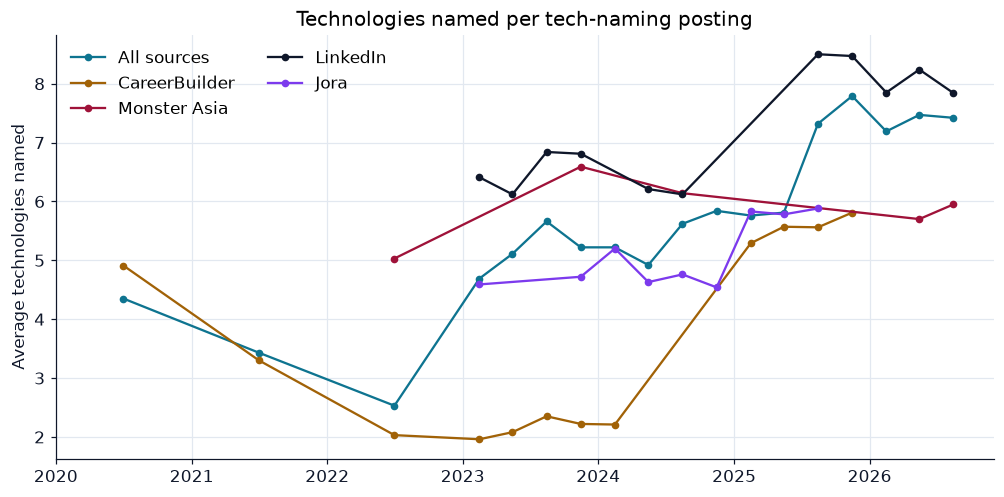

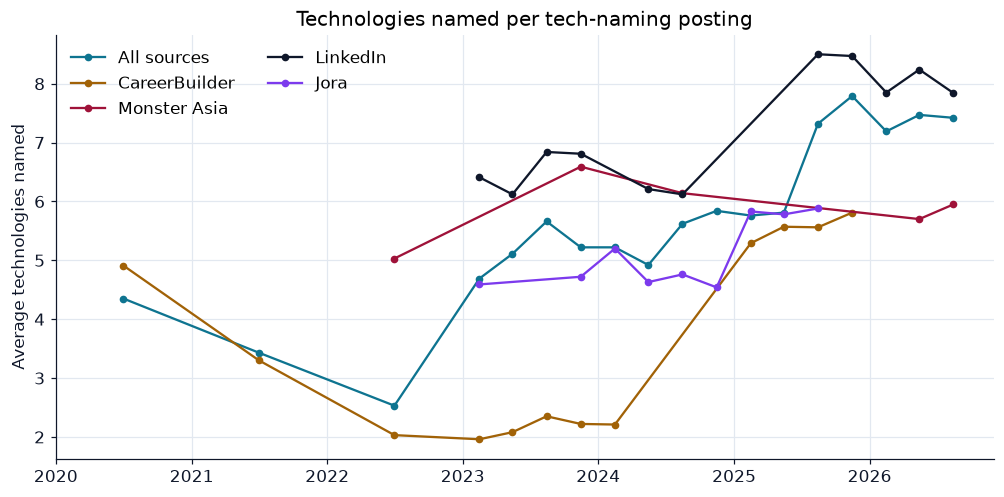

In [3]:
verbosity = t.verbosity_series(named)
fig = a.trend_lines(
    verbosity,
    "Technologies named per tech-naming posting",
    "Average technologies named",
    value="mean_techs",
)
a.save_chart(fig, "02-technologies-per-posting")
rows = [f.assign(source=n) for n, f in verbosity.items()]
a.save_table(pd.concat(rows).drop(columns="period_date"), "02-technologies-per-posting")
fig

## 2. What is named most

Share of tech-naming postings that name each technology, 2020 to October 2026, all sources.

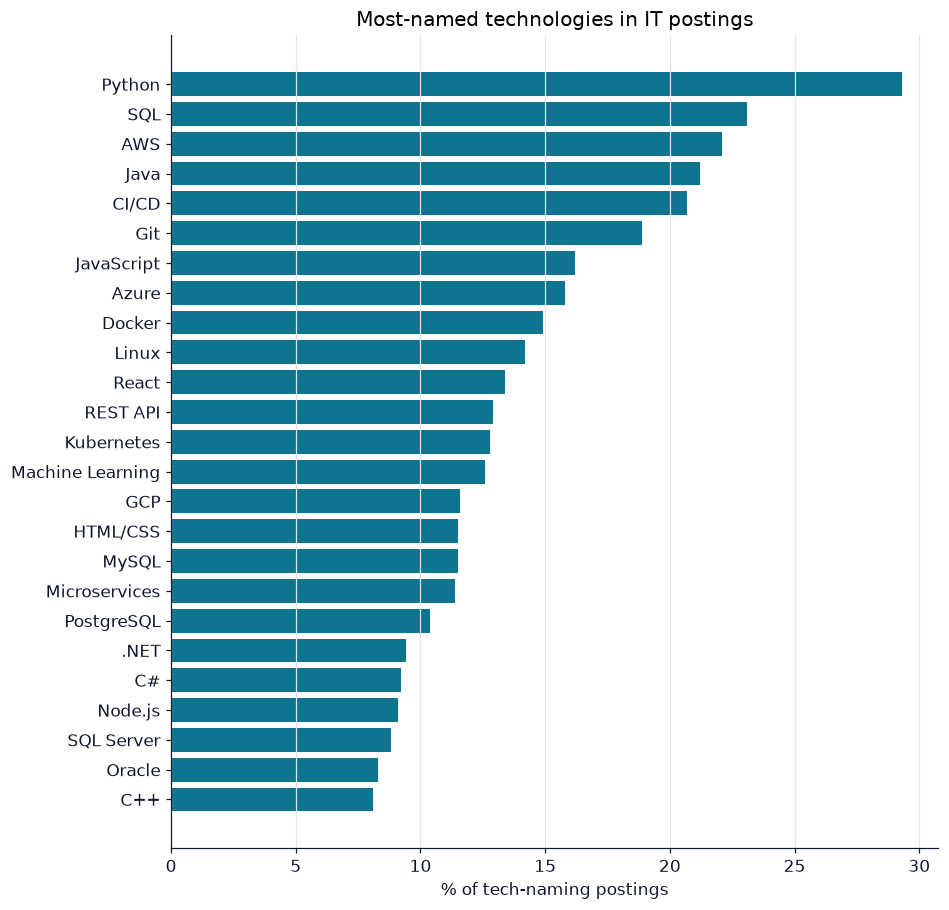

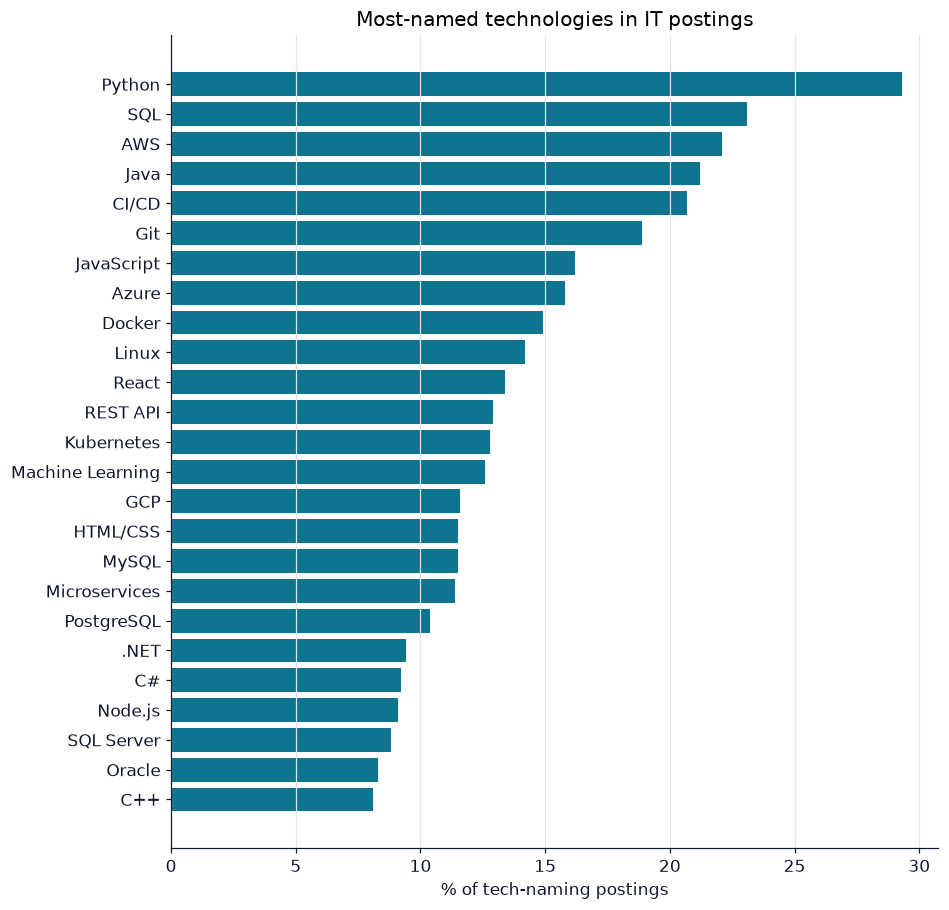

In [4]:
counts = t.technology_counts(named)
a.save_table(counts, "02-technology-counts")
fig = a.barh(
    counts.head(t.TOP_N),
    "tech",
    "share",
    "Most-named technologies in IT postings",
    "% of tech-naming postings",
)
a.save_chart(fig, "02-top-technologies")
fig

## 3. The top technologies over time

Each panel is one technology's share of tech-naming postings per period (years to 2022, quarters from 2023).

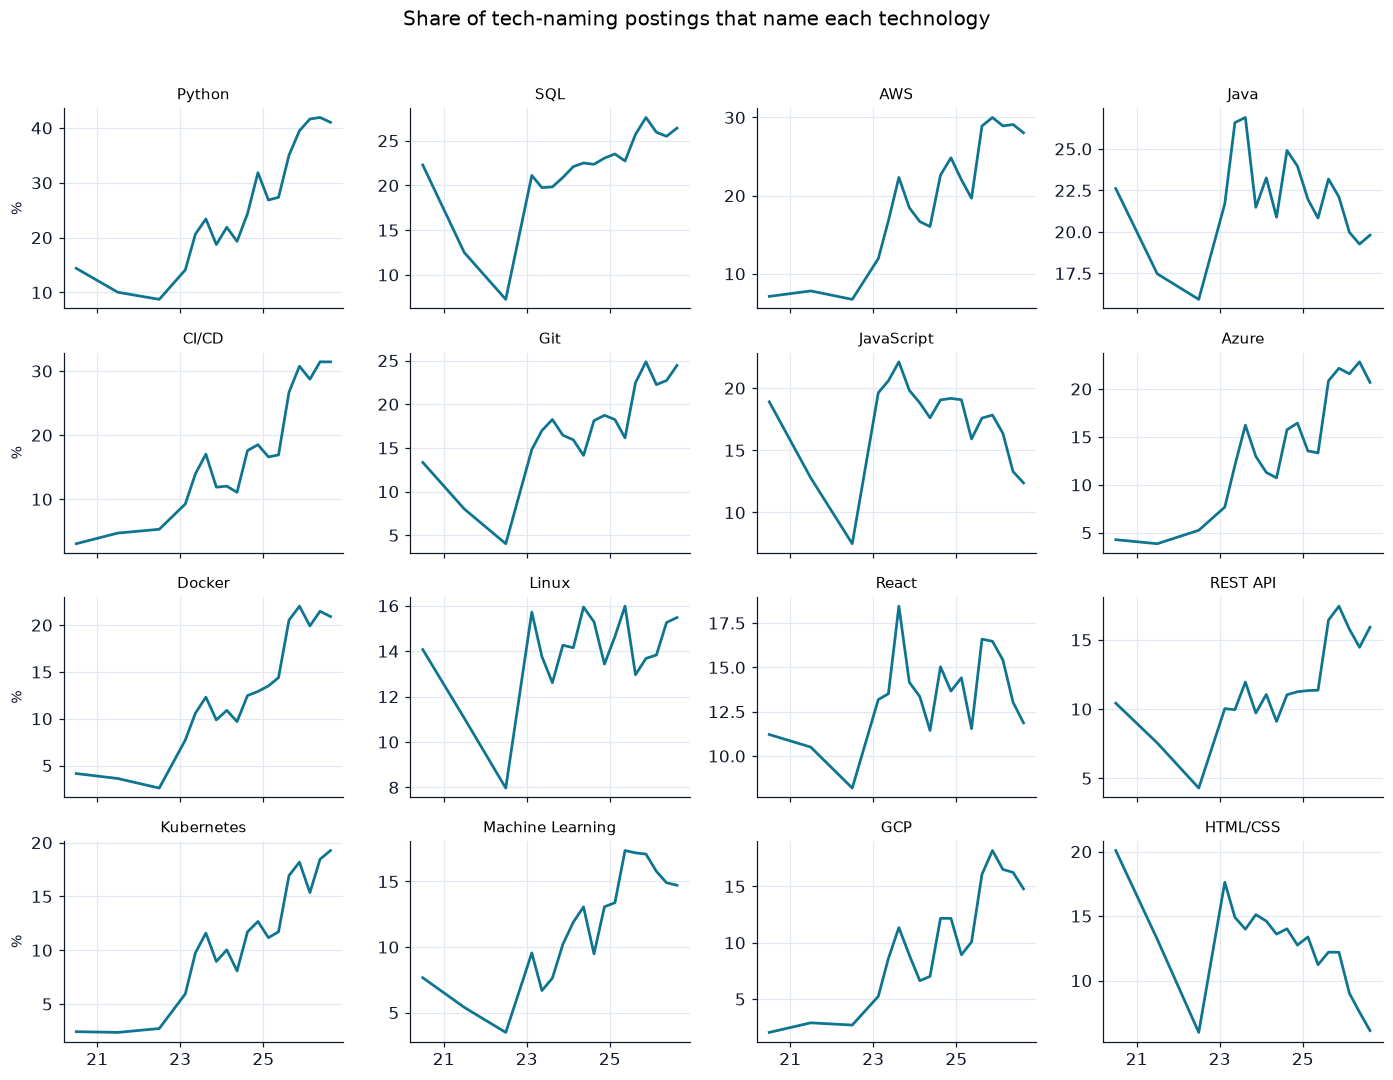

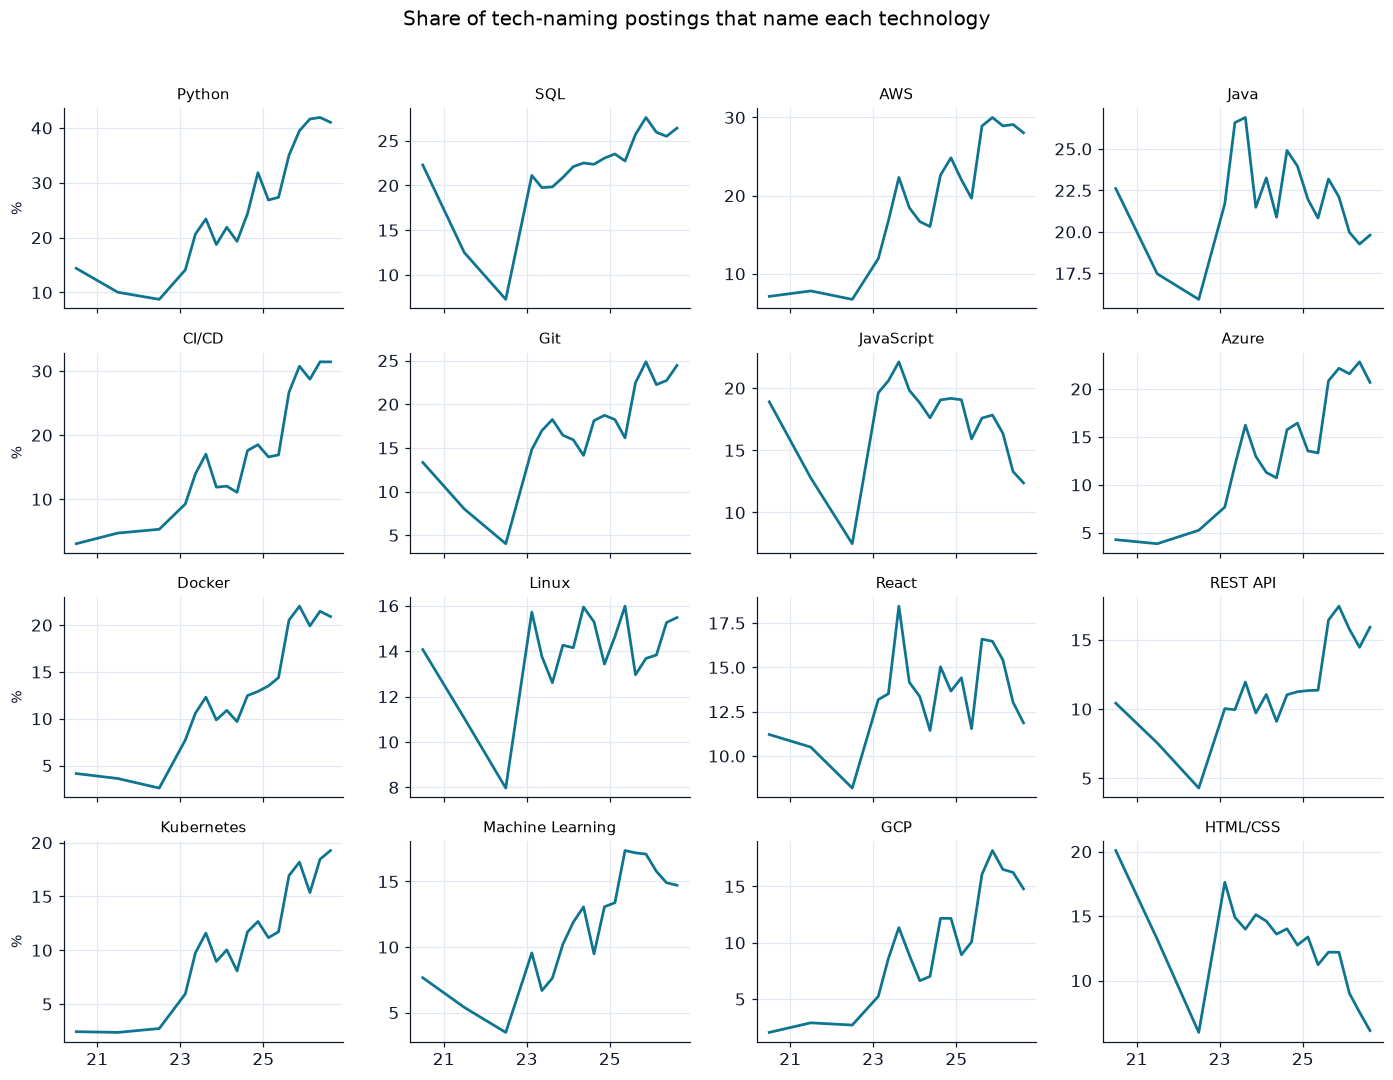

In [5]:
top = list(counts.tech.head(t.PANELS))
series = t.tech_series(named, top)
fig = a.small_multiples(series, "Share of tech-naming postings that name each technology", "%")
a.save_chart(fig, "02-technology-trends")
a.save_table(
    pd.concat([f.assign(tech=n) for n, f in series.items()]).drop(columns="period_date"),
    "02-technology-trends",
)
fig

## 4. Does it hold inside the control sources?

The same technologies for all sources, then Monster Asia only, then LinkedIn only. Where the control lines move the same way as the all-source line, the change is not an artefact of which sources were scraped. Monster Asia has few postings per quarter early on, so its lines are shorter.

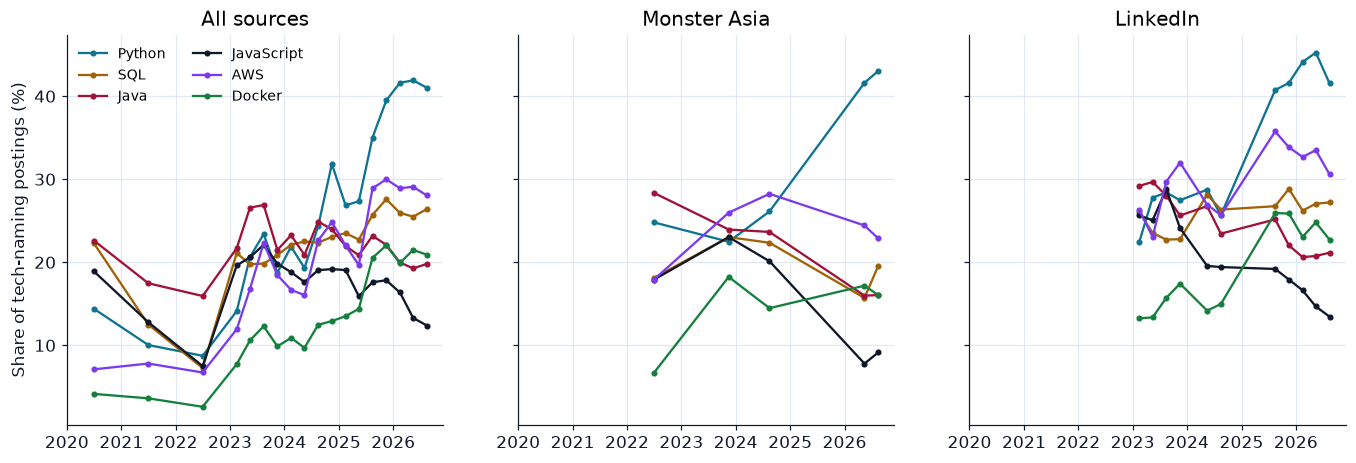

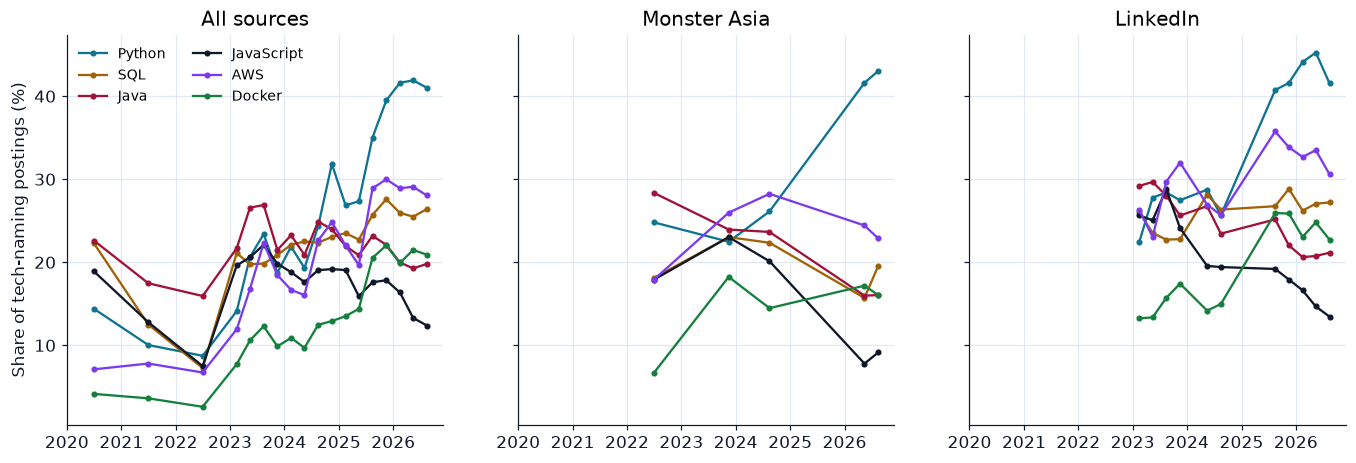

In [6]:
check = ["Python", "SQL", "Java", "JavaScript", "AWS", "Docker"]
fig = t.chart_source_check(named, check)
a.save_chart(fig, "02-source-check")
fig

## 5. Categories

Share of tech-naming postings that name at least one technology from each category.

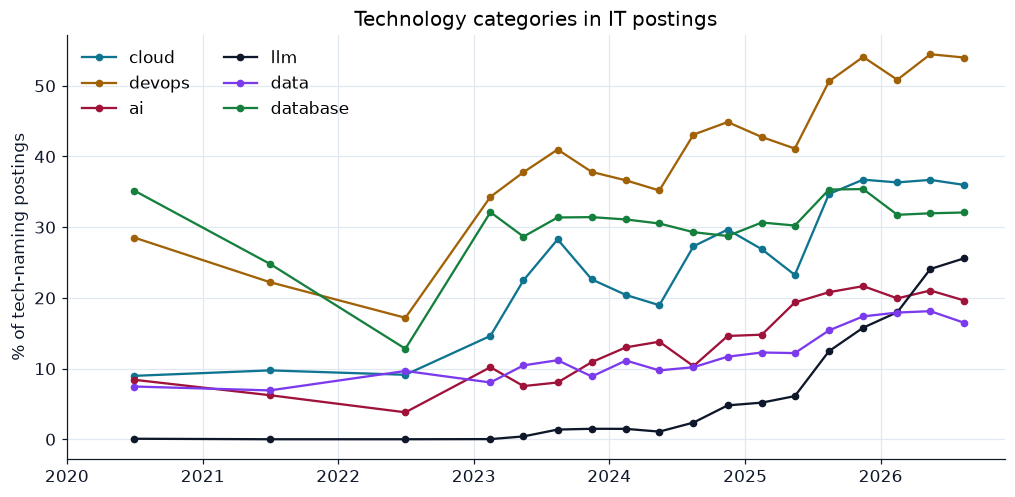

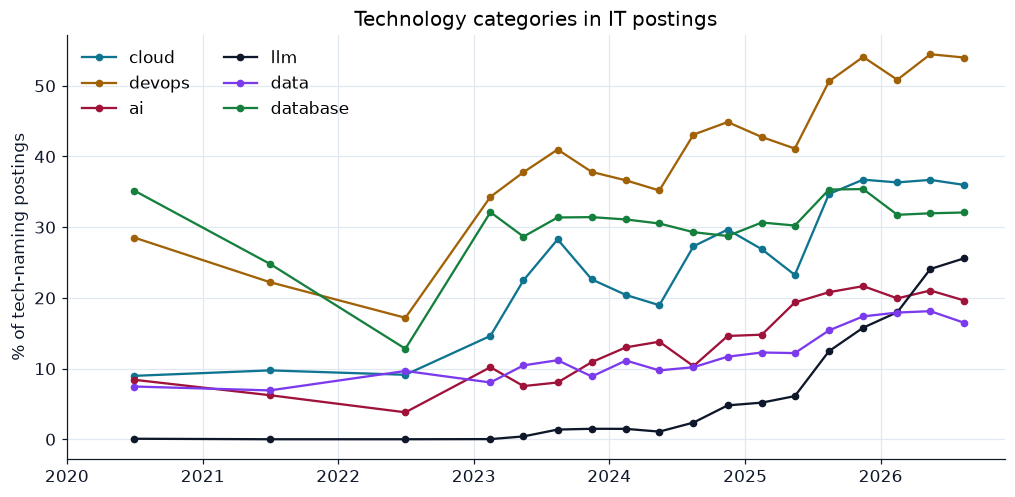

In [7]:
categories = ["cloud", "devops", "ai", "llm", "data", "database"]
cat_series = t.category_series(named, categories)
fig = a.trend_lines(cat_series, "Technology categories in IT postings", "% of tech-naming postings")
a.save_chart(fig, "02-categories")
rows = [f.assign(category=n) for n, f in cat_series.items()]
a.save_table(pd.concat(rows).drop(columns="period_date"), "02-categories")
fig

## 6. Risers and fallers

Each control source against itself, in percentage points of its tech-naming postings: Monster Asia 2021–22 against January 2025 onward, LinkedIn 2023–24 against January 2025 onward. A technology that moves the same way in both is a trend we can trust.

In [8]:
names = list(counts.tech.head(20))
monster = t.shift_table(named, names, ("2021-01", "2022-12"), "monsterasia_vn")
linkedin = t.shift_table(named, names, ("2023-01", "2024-12"), "linkedin_vn")
a.save_table(monster, "02-shift-monster-asia")
a.save_table(linkedin, "02-shift-linkedin")
both = monster.merge(linkedin, on="tech", suffixes=("_monster", "_linkedin"))
both.sort_values("change_linkedin", ascending=False)

,tech,early_monster,late_monster,change_monster,early_linkedin,late_linkedin,change_linkedin
0,Python,23.6,43.1,19.5,28.2,42.5,14.3
1,CI/CD,7.4,22.6,15.2,21.4,34.1,12.7
4,Docker,7.2,13.1,5.9,15.3,24.0,8.7
3,Machine Learning,3.9,10.3,6.4,8.9,15.5,6.6
8,PostgreSQL,2.9,6.2,3.3,10.5,15.7,5.2
2,Kubernetes,6.4,13.2,6.8,16.2,20.8,4.6
9,AWS,19.3,21.5,2.2,28.3,32.5,4.2
14,Azure,18.6,14.7,-3.9,19.9,24.0,4.1
11,GCP,8.4,10.0,1.6,14.7,18.8,4.1
12,REST API,9.1,8.3,-0.8,14.4,18.1,3.7


## 7. How good is the dictionary?

Where the board supplies its own `SKILLS` tags we can compare. `found_in_text` is the share of technologies the tags list that our text matching also found; `text_in_tags` is the reverse. The tags are patchy (many boards do not fill them), so this is a check on recall, not a ground truth.

In [9]:
agreement = t.tag_agreement(df)
a.save_table(agreement, "02-dictionary-vs-tags")
agreement

,year,postings,tag_mentions,found_in_text,text_in_tags
0,2020,1607,1446,66.5,19.5
1,2021,9266,7377,53.2,27.0
2,2022,6864,4041,40.3,36.0
3,2023,7146,8915,72.9,50.2
4,2024,6578,17460,54.7,57.3
5,2025,4297,2910,83.3,20.7
6,2026,13579,14567,87.1,20.4


## Findings

1. **Most-named technologies (all sources, 2020 to October 2026):** Python 29 %, SQL 23 %, AWS 22 %, Java 21 %, CI/CD 21 %, Git 19 %, JavaScript 16 %, Azure 16 %, Docker 15 %, Linux 14 % of tech-naming postings. "Oracle" (8 %) includes the company's name, and "Git" includes GitHub, so treat those two as upper bounds.
2. **Descriptions got longer, which inflates every share.** Technologies named per tech-naming posting rise from about 4.4 (2020) to about 7.4 (2026) across all sources, and CareerBuilder jumped from about 2 to about 5.5 in 2025 when its descriptions doubled in length. A before/after inside CareerBuilder across 2024–25 is not valid.
3. **Direction holds in both control sources.** Rising in Monster Asia (2021–22 to 2025 on) and LinkedIn (2023–24 to 2025 on): Python 24→43 and 28→43 %, CI/CD 7→23 and 21→34 %, Docker 7→13 and 15→24 %, Machine Learning 4→10 and 9→16 %, Kubernetes 6→13 and 16→21 %. Falling in both: Java 31→16 and 27→22 %, JavaScript 15→9 and 24→16 %, HTML/CSS 12→5 and 16→9 %, React 13→7 and 20→16 %, .NET 6→3 and 12→7 %, C# 14→5 and 11→8 %.
4. **Categories (all sources, so inflated by point 2).** Since 2023-Q1: LLM tools go from about 0 % to 5 % (2025-Q1) to 26 % (2026-Q3), far beyond any description effect; cloud rises 15→36 %, data 8→16 % and AI/ML 10→20 %, each about 2× or more against roughly 1.6× for the description effect; DevOps (34→54 %) is about the size of the description effect, so it is not shown to be growing; databases are flat at about 31–32 %.
5. **The dictionary agrees with the boards' own tags where they exist.** In 2025–26, 83–87 % of the technologies the `SKILLS` tags list are also found by text matching. The tags cover only about 20 % of what the text names in those years, so they cannot replace the text. In 2021–22 agreement is lower (40–53 %), because older tags mix job titles and skills.

**What this notebook cannot say:** how fast any single technology grew in absolute terms. It can say which ones moved the same way in two independent sources, and by roughly how much.
